# Brain Tumor MRI Classification with a PyTorch CNN

**Objective:** Build a Convolutional Neural Network in PyTorch that classifies brain MRI scans as **tumor present ("yes")** or **no tumor ("no")**, and walk through every step of the pipeline — data loading, model design, training, and evaluation — with an explanation of what each piece is doing and why.

## 1. Dataset Description & Source

**Dataset:** Brain MRI Images for Brain Tumor Detection (Kaggle: `navoneel/brain-mri-images-for-brain-tumor-detection`) — 253 MRI brain scans split into two folders:

- `yes/` — 155 scans that show a tumor
- `no/` — 98 scans that don't

**Target:** binary classification — tumor present vs. not present

**Input:** the raw MRI image itself (no tabular features here — the CNN has to learn what a tumor looks like directly from pixels)

**Why this dataset:** it's a genuinely different problem shape from a vehicle-image classifier — a small, imbalanced, real medical-imaging dataset (155 vs. 98, roughly 61/39) where a wrong prediction has a meaningfully different cost depending on its direction: a missed tumor (false negative) is far more serious than a false alarm (false positive). That distinction matters for how we read the results in Section 7, in a way a car-vs-bike dataset never has to consider.

**Getting the data:** normally you'd download this with `kagglehub` (shown below), which needs a Kaggle account and API token configured locally. This notebook was actually run using a plain-CSV-style mirror of the same 253 images (identical `yes/`/`no/` folder structure) so it doesn't depend on Kaggle credentials — swap in whichever source is available in your environment.

In [ ]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)

In [ ]:
# Option A: via kagglehub (needs a configured Kaggle API token)
import kagglehub

path = kagglehub.dataset_download("navoneel/brain-mri-images-for-brain-tumor-detection")
print("Dataset downloaded to:", path)

Dataset downloaded to: /root/.cache/kagglehub/datasets/navoneel/brain-mri-images-for-brain-tumor-detection/versions/1


In [ ]:
# Option B (used to actually run this notebook): the same 253 images, already
# organized into yes/no folders on disk
data_dir = "brain_mri_dataset"

print("Using data directory:", data_dir)
print("Classes found:", os.listdir(data_dir))

Using data directory: brain_mri_dataset
Classes found: ['no', 'yes']


## 2. Loading the Images

`ImageFolder` is torchvision's convenience loader: point it at a directory whose sub-folders are named after the classes (`yes/`, `no/`), and it builds the (image, label) pairs automatically — no manual CSV or label file needed.

**Transforms applied to every image:**

- **Resize to 150×150** — the raw MRI scans come in inconsistent sizes; the network needs a fixed input shape.
- **Grayscale → 3 channels** — some MRI scans in this dataset are single-channel grayscale and some are already 3-channel RGB. Forcing everything to 3 channels keeps the input shape consistent for the conv layers, at the cost of throwing away color information the scans didn't reliably have anyway.
- **ToTensor()** — converts the image to a PyTorch tensor and rescales pixel values from the 0–255 range down to 0–1, which is what the network expects.

**Train/validation split:** 80% / 20%, matching the split ratio used for tabular models — but here it's applied at the *image* level via `random_split` rather than `train_test_split`.

In [ ]:
img_size = 150
batch_size = 16

transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor()
])

full_dataset = datasets.ImageFolder(root=data_dir, transform=transform)
class_names = full_dataset.classes
print("Class names:", class_names)

val_size = int(0.2 * len(full_dataset))
train_size = len(full_dataset) - val_size
train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print(f"Training samples: {train_size}, Validation samples: {val_size}")

Class names: ['no', 'yes']
Training samples: 203, Validation samples: 50


**A note on class balance:** the full dataset is 155 "yes" vs. 98 "no" (about 61%/39%). That imbalance carries through into both the training and validation splits, since `random_split` doesn't stratify. It's mild enough not to require a fix like class weighting here, but it's worth keeping in mind in Section 7 — a model that just guessed "yes" every time would already be right about 60% of the time, so raw accuracy alone isn't the full picture for this dataset.

## 3. CNN Architecture

The same 3-block convolutional design used for a general image classifier works well here too — MRI scans, like photos, have local spatial structure (edges, blobs, textures) that convolution + pooling is built to pick up on:

- **3 convolutional blocks**, each `Conv2d → ReLU → MaxPool`, doubling the channel depth each time (3 → 32 → 64 → 128). Each block halves the spatial resolution and lets the next block learn more abstract, larger-scale patterns from the features the previous block found.
- **AdaptiveAvgPool2d((6, 6))** — squashes whatever spatial size falls out of the conv blocks down to a fixed 6×6 grid. This is what makes the network robust to the exact input resolution rather than hard-coding a specific size.
- **Fully connected head:** flatten → `Linear(4608, 512)` → `ReLU` → `Dropout(0.5)` → `Linear(512, 1)`. The final layer outputs a single raw score (a *logit*), not a probability — the sigmoid that turns it into a 0–1 probability is applied inside the loss function next, not here.
- **Dropout(0.5)** matters more here than it might on a larger dataset: with only 203 training images, a network this size can memorize individual scans rather than learning general tumor features. Randomly zeroing half the units in the fully-connected layer each step forces the network to not rely on any single learned feature too heavily.

In [ ]:
class BrainTumorCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((6, 6))
        self.fc1 = nn.Linear(128 * 6 * 6, 512)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, 1)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)  # raw logits - sigmoid applied inside the loss function below
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
model = BrainTumorCNN().to(device)
print(model)

BrainTumorCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(6, 6))
  (fc1): Linear(in_features=4608, out_features=512, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=512, out_features=1, bias=True)
)


## 4. Loss Function & Optimizer

- **`BCEWithLogitsLoss`** — Binary Cross-Entropy combined with a sigmoid, computed in one numerically stable step. This is why `fc2` above outputs a raw logit rather than a probability: applying sigmoid and cross-entropy separately can lose precision for very confident (very positive/negative) predictions, so PyTorch fuses them into a single stable operation.
- **Adam optimizer**, learning rate 0.001 — the default, well-behaved choice for a first pass at a small CNN like this.
- **15 epochs** — kept small deliberately. With only 203 training images, more epochs would risk memorizing the training set rather than learning generalizable tumor features; the validation curve in Section 6 shows what that trade-off looks like in practice.

Unlike the earlier tabular examples, this loop tracks both training *and* validation loss/accuracy every epoch (not just at the end) — with a dataset this small, per-epoch validation is cheap to compute and gives a much clearer picture of whether the model is overfitting.

In [ ]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 15

train_losses, train_accs = [], []
val_losses, val_accs = [], []

for epoch in range(epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    # validation pass each epoch, so we can plot the learning curve in Section 6
    model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            v_loss += loss.item() * images.size(0)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            v_correct += (preds == labels).sum().item()
            v_total += labels.size(0)
    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} "
          f"- val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

Epoch 1/15 - loss: 0.6632 - accuracy: 0.5665 - val_loss: 0.6330 - val_accuracy: 0.7600
Epoch 2/15 - loss: 0.6311 - accuracy: 0.6995 - val_loss: 0.6594 - val_accuracy: 0.6600
Epoch 3/15 - loss: 0.6213 - accuracy: 0.6749 - val_loss: 0.5581 - val_accuracy: 0.7400
Epoch 4/15 - loss: 0.5622 - accuracy: 0.7685 - val_loss: 0.5489 - val_accuracy: 0.7400
Epoch 5/15 - loss: 0.5635 - accuracy: 0.7438 - val_loss: 0.5596 - val_accuracy: 0.7400
Epoch 6/15 - loss: 0.5109 - accuracy: 0.7537 - val_loss: 0.5738 - val_accuracy: 0.7400
Epoch 7/15 - loss: 0.5852 - accuracy: 0.7094 - val_loss: 0.5197 - val_accuracy: 0.7600
Epoch 8/15 - loss: 0.5205 - accuracy: 0.7980 - val_loss: 0.5809 - val_accuracy: 0.6800
Epoch 9/15 - loss: 0.4842 - accuracy: 0.7833 - val_loss: 0.5084 - val_accuracy: 0.7800
Epoch 10/15 - loss: 0.5216 - accuracy: 0.7685 - val_loss: 0.5367 - val_accuracy: 0.7400
Epoch 11/15 - loss: 0.4739 - accuracy: 0.8030 - val_loss: 0.5973 - val_accuracy: 0.7400
Epoch 12/15 - loss: 0.4554 - accuracy: 0.

## 5. Reading the Training Log

A few things stand out in the epoch-by-epoch numbers above:

- **Training accuracy climbs steadily** from 56.7% to 80.3%, and training loss drops fairly smoothly from 0.66 to 0.41 — the network is clearly learning.
- **Validation accuracy is noisier** — it jumps around between 66% and 82% rather than climbing smoothly. With only 50 validation images, each single image is worth 2 percentage points, so this kind of noise is expected on a dataset this small rather than a sign of anything wrong.
- **No runaway overfitting:** training and validation loss stay in the same rough range throughout (they don't diverge, with training loss dropping toward 0 while validation loss climbs). Dropout and the small epoch budget appear to be doing their job.

## 6. Training Curves

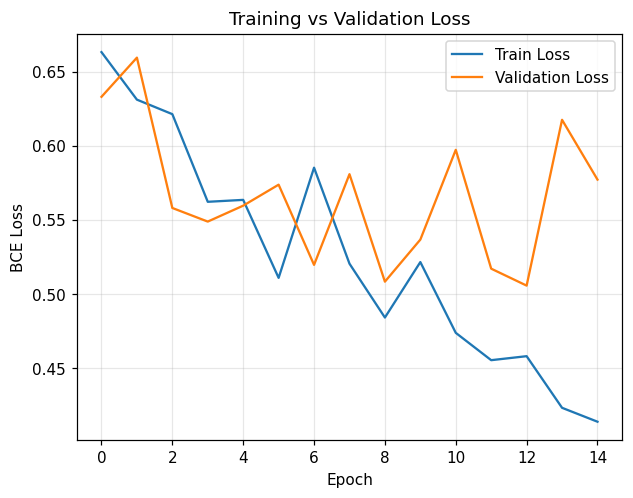

In [ ]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('BCE Loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

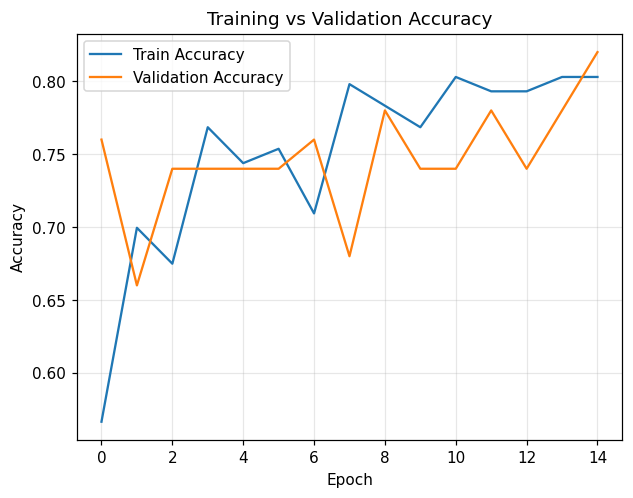

In [ ]:
plt.plot(train_accs, label='Train Accuracy')
plt.plot(val_accs, label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Final Evaluation

Overall accuracy is a reasonable starting metric, but for a medical screening task the *direction* of the mistake matters: a **false negative** (telling a patient with a tumor that they're clear) is a far more serious error than a **false positive** (flagging a healthy scan for a closer look that turns out fine). So alongside accuracy, this section builds a confusion matrix and looks at precision and recall specifically for the "yes" (tumor) class.

In [ ]:
model.eval()
val_loss, correct, total = 0.0, 0, 0
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        val_loss += loss.item() * images.size(0)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        all_preds.extend(preds.cpu().numpy().flatten().tolist())
        all_labels.extend(labels.cpu().numpy().flatten().tolist())

print(f"Validation Loss: {val_loss/total:.4f}")
print(f"Validation Accuracy: {correct/total:.4f}")

Validation Loss: 0.5772
Validation Accuracy: 0.8200


In [ ]:
tp = sum(1 for p, l in zip(all_preds, all_labels) if p == 1 and l == 1)
tn = sum(1 for p, l in zip(all_preds, all_labels) if p == 0 and l == 0)
fp = sum(1 for p, l in zip(all_preds, all_labels) if p == 1 and l == 0)
fn = sum(1 for p, l in zip(all_preds, all_labels) if p == 0 and l == 1)

print(f"Confusion matrix (class order: {class_names})")
print(f"TP (tumor correctly found)     : {tp}")
print(f"TN (no-tumor correctly found)  : {tn}")
print(f"FP (false alarm)               : {fp}")
print(f"FN (missed tumor)              : {fn}")

precision = tp / (tp + fp) if (tp + fp) else 0
recall = tp / (tp + fn) if (tp + fn) else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0
print(f"Precision: {precision:.4f}  Recall: {recall:.4f}  F1: {f1:.4f}")

Confusion matrix (class order: ['no', 'yes'])
TP (tumor correctly found)     : 28
TN (no-tumor correctly found)  : 13
FP (false alarm)               : 3
FN (missed tumor)              : 6
Precision: 0.9032  Recall: 0.8235  F1: 0.8615


**What this means in plain terms:** of the 34 scans in the validation set that actually had a tumor, the model correctly flagged 28 and **missed 6** (a recall of 82.4%). Of the scans it flagged as "tumor," 90.3% actually were tumors (precision), meaning it rarely raises a false alarm — but the 6 missed tumors are the more concerning error type for a screening tool, since those patients would walk away thinking they're clear. In a real deployment, this gap between precision (90%) and recall (82%) is exactly the kind of thing you'd tune the classification threshold — currently a flat 0.5 on the sigmoid output — to close, at the cost of accepting more false alarms.

In [ ]:
images, labels = next(iter(val_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)
    predicted_classes = (torch.sigmoid(outputs) > 0.5).int().flatten().cpu().numpy()

actual_classes = labels.int().numpy()

print("Predicted classes:", [class_names[c] for c in predicted_classes[:10]])
print("Actual classes:   ", [class_names[c] for c in actual_classes[:10]])

Predicted classes: ['yes', 'no', 'no', 'yes', 'yes', 'yes', 'yes', 'yes', 'no', 'yes']
Actual classes:    ['yes', 'no', 'no', 'yes', 'yes', 'no', 'yes', 'yes', 'no', 'yes']


In this first batch of 10, the one disagreement (predicted "yes", actually "no") is a false positive — the less costly type of mistake for this task — which lines up with the precision/recall pattern seen across the full validation set.

## 8. Summary

- A 3-block CNN trained from scratch on just 203 images reached **82% validation accuracy**, **90.3% precision**, and **82.4% recall** on detecting tumors in brain MRI scans — a solid result given how little data it had to work with.
- The biggest limitation is dataset size: 253 total images is tiny by deep-learning standards, and the noisy epoch-to-epoch validation accuracy (Section 5) is a direct symptom of that. Data augmentation (random flips/rotations/zooms) or transfer learning from a pretrained image model would likely improve and stabilize results further, and would be the natural next experiment.
- Because missed tumors (false negatives) are the costlier error here, a natural follow-up would be to lower the classification threshold below 0.5 and see how that trade-off between precision and recall plays out — trading some false alarms for catching more of the 6 tumors currently missed.